<center><h1>Wagner_Anton_HW6</h1></center>

Name: Anton Wagner
<br>
Github Username: AntonW1
<br>
USC ID: 2245157283

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import math
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score, RocCurveDisplay

In [2]:
!pip install xgboost
!pip install imbalanced-learn

In [3]:
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [4]:
train_data_path = '../Homework 6 Data/aps_failure_training_set.csv'
test_data_path = '../Homework 6 Data/aps_failure_test_set.csv'

train_df = pd.read_csv(train_data_path, skiprows=20, na_values='na')
test_df = pd.read_csv(test_data_path, skiprows=20, na_values='na')

In [5]:
train_df.head(5)

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [6]:
test_df.head(5)

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,20.0,12.0,0.0,0.0,0.0,0.0,0.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,68.0,40.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,212.0,112.0,0.0,0.0,0.0,0.0,0.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,NaN,1010.0,936.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,NaN,156.0,140.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [7]:
train_df.info(show_counts=True, verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 171 columns):
 #    Column  Non-Null Count  Dtype  
---   ------  --------------  -----  
 0    class   60000 non-null  str    
 1    aa_000  60000 non-null  int64  
 2    ab_000  13671 non-null  float64
 3    ac_000  56665 non-null  float64
 4    ad_000  45139 non-null  float64
 5    ae_000  57500 non-null  float64
 6    af_000  57500 non-null  float64
 7    ag_000  59329 non-null  float64
 8    ag_001  59329 non-null  float64
 9    ag_002  59329 non-null  float64
 10   ag_003  59329 non-null  float64
 11   ag_004  59329 non-null  float64
 12   ag_005  59329 non-null  float64
 13   ag_006  59329 non-null  float64
 14   ag_007  59329 non-null  float64
 15   ag_008  59329 non-null  float64
 16   ag_009  59329 non-null  float64
 17   ah_000  59355 non-null  float64
 18   ai_000  59371 non-null  float64
 19   aj_000  59371 non-null  float64
 20   ak_000  55600 non-null  float64
 21   al_000  59358 non-nul

Techniques for missing data are either removal or imputation. Since there are a large number of missing values, too much data would be lost with removal. There are some columns that are missing the majority of values, but since 170 features are needed for part ii., they can't be dropped.
<br>
There are various methods of imputation, including using the columns' mean, median, or mode in place on null values, but this can bias the data if the values are not missing at random. The positive is that it has little impact on the sample mean which is needed for part ii.. Imputation can also be done based on KNN or regression, which work well if the missing values are related to values of other features. There are also more complex methods of chained multiple imputation (MICE). However, with so many features and rows, these methods are too computationally intensive.
<br>
I will use median imputation as the data is too skewed for mean.
<br>

Sources:
<br>
https://medium.com/@adnan.mazraeh1993/certainly-212c21c25408

In [8]:
# Median imputation

train_df_no_target = train_df.drop(columns=['class'])
test_df_no_target = test_df.drop(columns=['class'])
train_columns = train_df_no_target.columns
test_columns = test_df_no_target.columns

for column in train_columns:
    train_df[column] = train_df[column].fillna(train_df[column].median())

for column in test_columns:
    test_df[column] = test_df[column].fillna(test_df[column].median())
# Test data is filled separately from train as mentioned by footnote 1

#### (ii) Calculate the coefficient of variation

In [9]:
CV = train_df[train_columns].std() / train_df[train_columns].mean()
CV.sort_values(inplace=True, ascending=False)
print(CV)

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
             ...    
bo_000      0.792383
bp_000      0.753392
bq_000      0.718534
br_000      0.689112
cd_000      0.000000
Length: 170, dtype: float64


#### (iii) Plot a correlation matrix

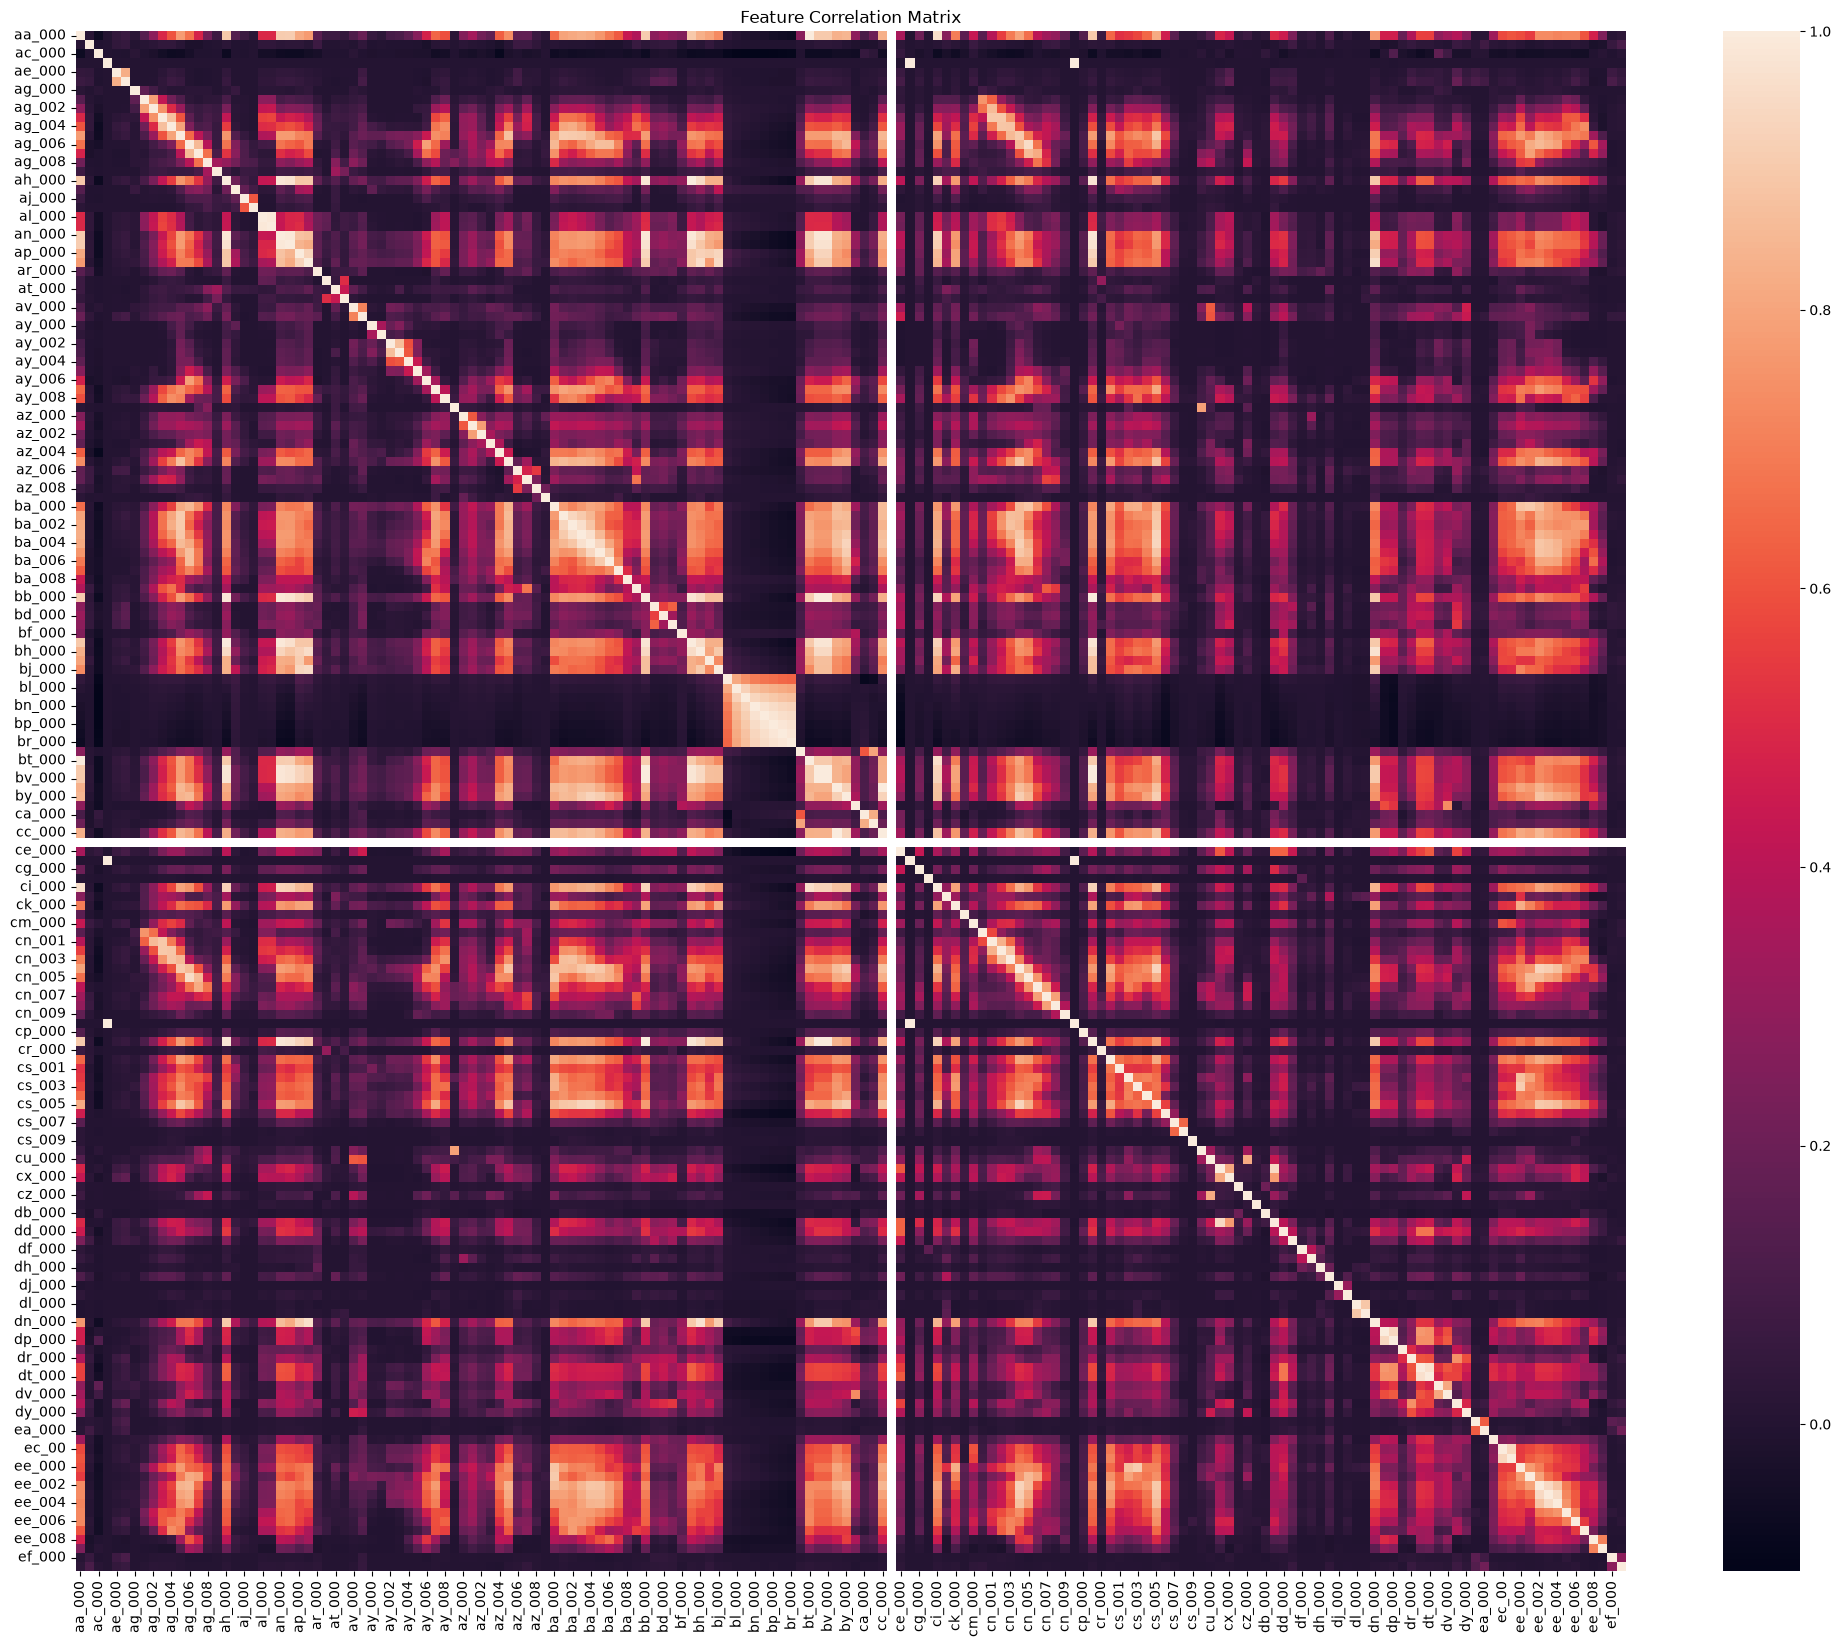

In [10]:
correlation_matrix = train_df[train_columns].corr()
plt.figure(figsize=(25, 20))
sns.heatmap(correlation_matrix)
plt.title('Feature Correlation Matrix')
plt.show()

#### (iv) Make scatter plots and box plots

In [11]:
num_features = math.floor(math.sqrt(170))
print(f'{num_features} features')

13 features


In [12]:
print(CV.head(13))
CV_features = CV.head(num_features).index

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
dtype: float64


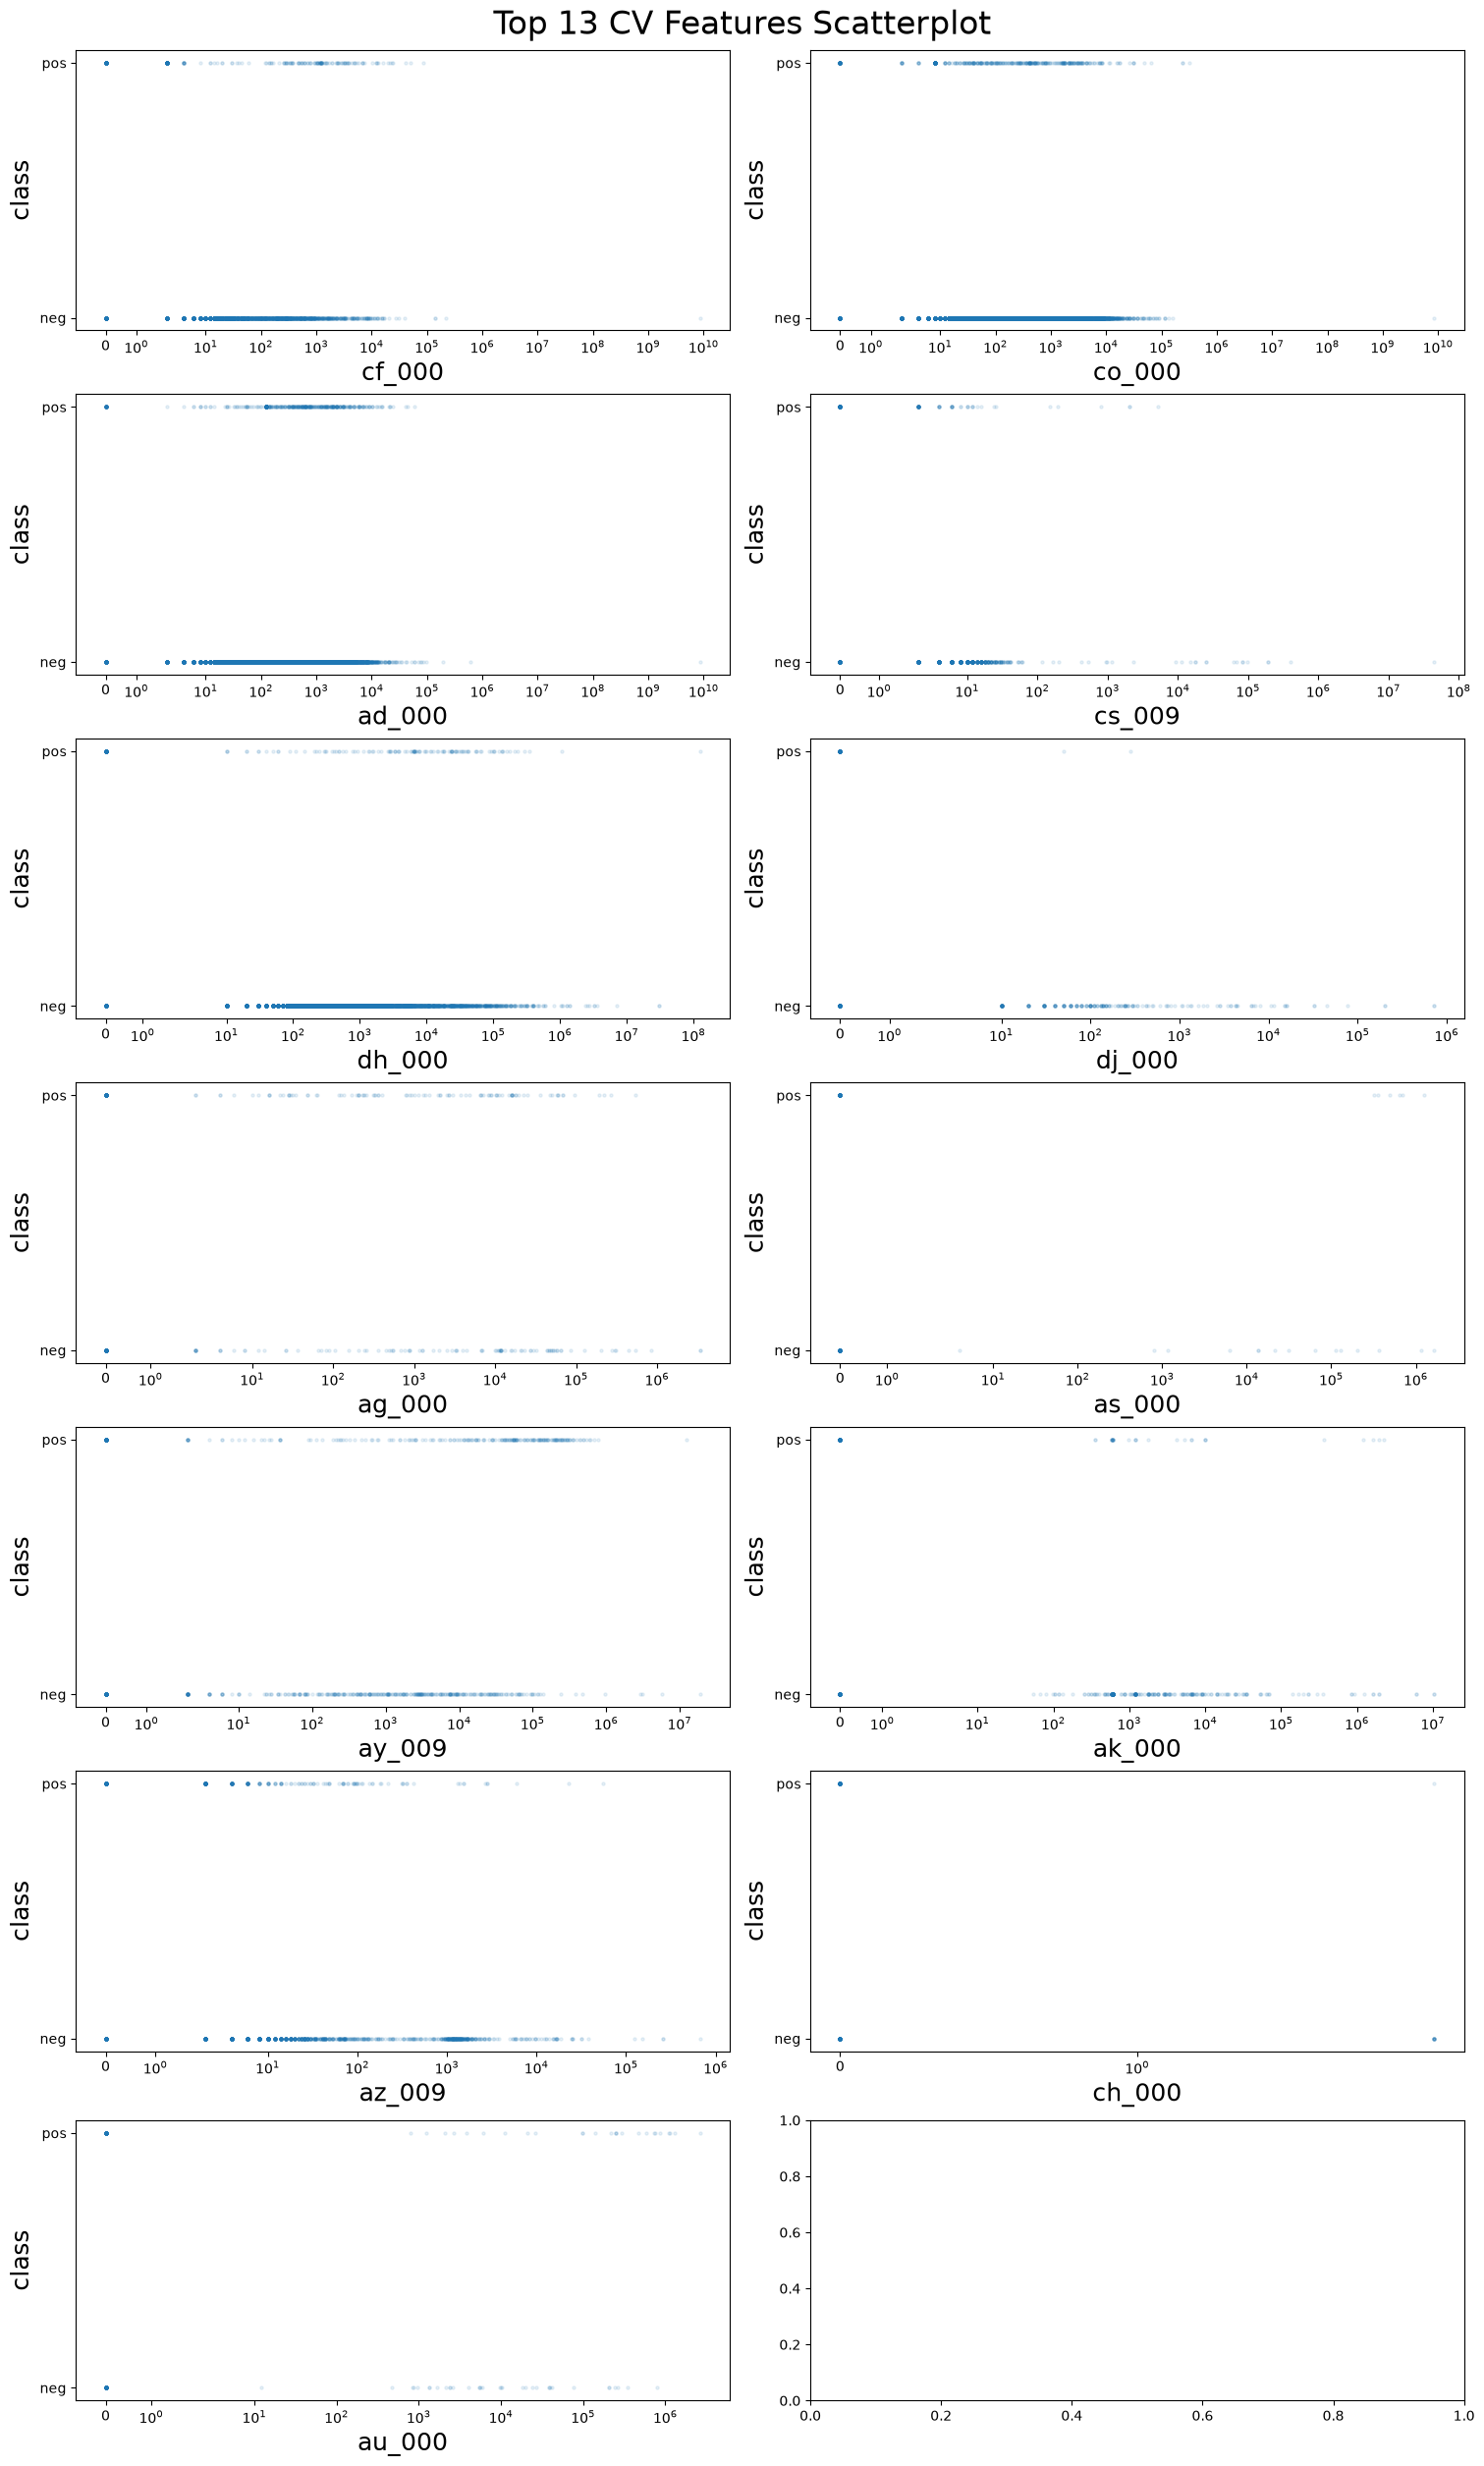

In [13]:
fig, axes = plt.subplots(7, 2, figsize=[15, 25], constrained_layout=True)
axes = axes.flatten()

for i, feature in enumerate(CV_features):
    axes[i].scatter(train_df[feature], train_df['class'], s=5, alpha=0.10)
    axes[i].set_xlabel(feature, fontsize=18)
    axes[i].set_xscale('symlog')
    axes[i].set_ylabel('class', fontsize=18)

plt.suptitle('Top 13 CV Features Scatterplot', fontsize=24)
plt.show()

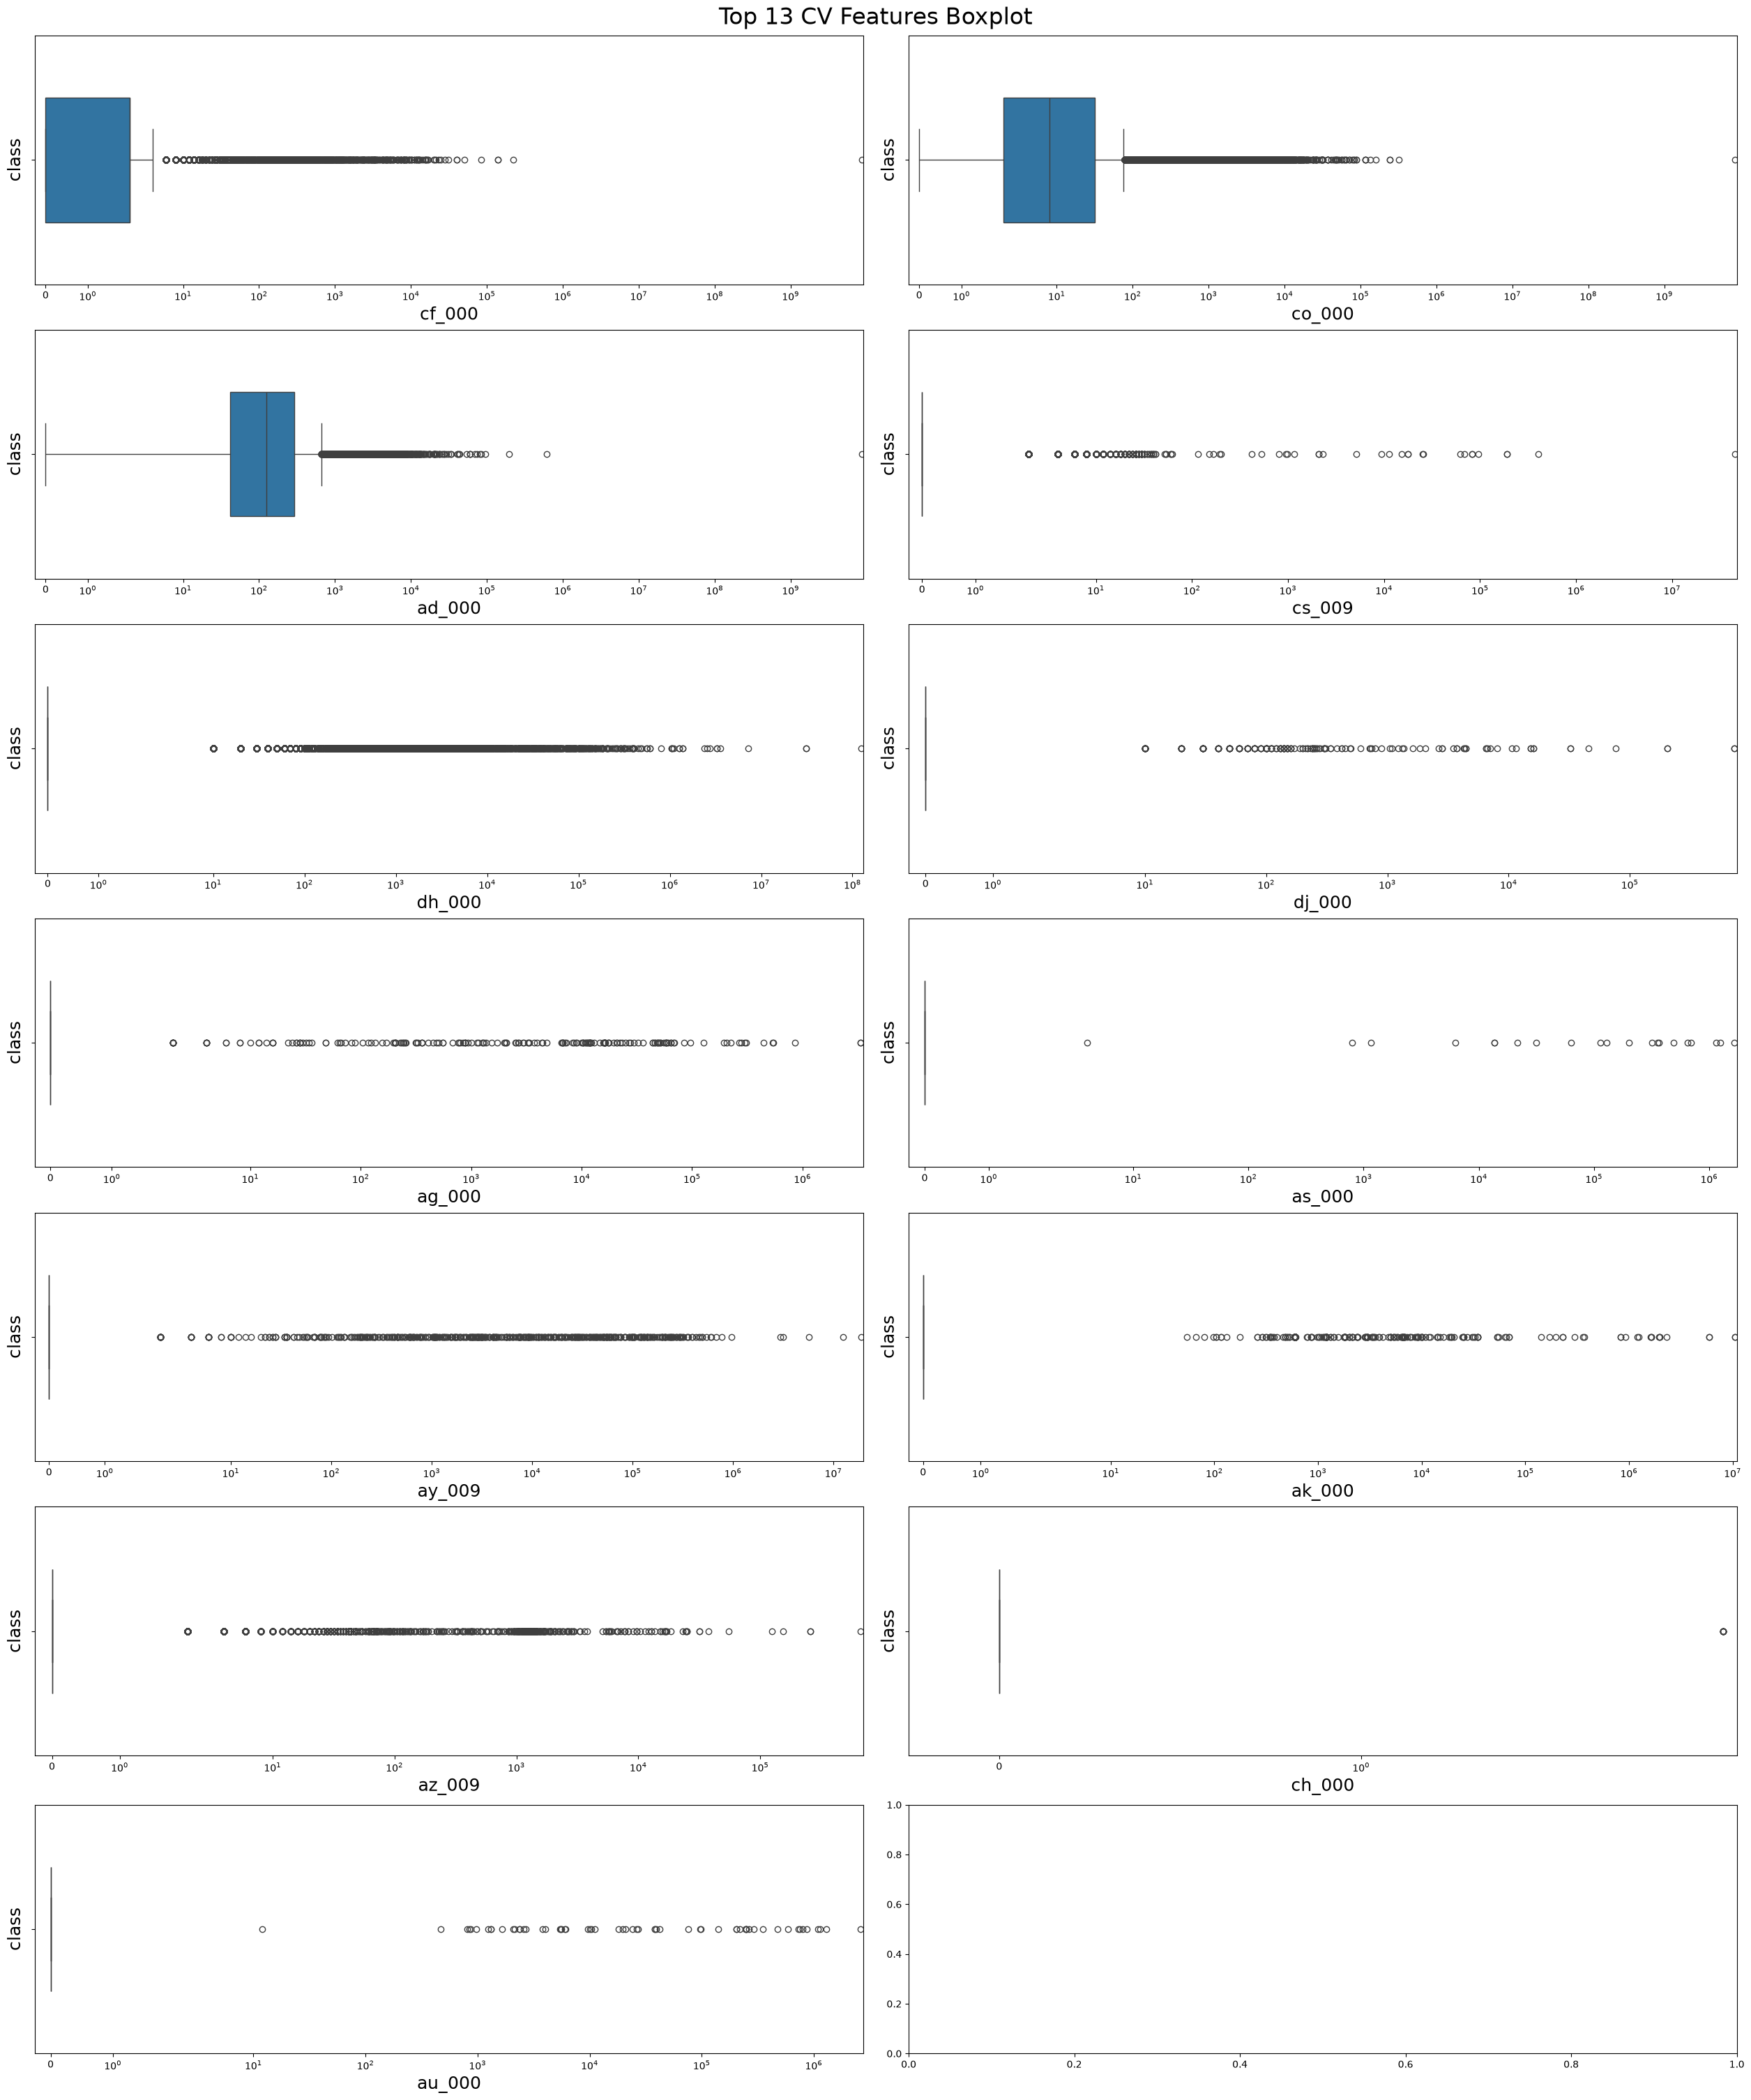

In [14]:
fig, axes = plt.subplots(7, 2, figsize=[25, 30], constrained_layout=True)
axes = axes.flatten()

for i, feature in enumerate(CV_features):
    sns.boxplot(x=train_df[feature], ax=axes[i], width=0.5)
    axes[i].set_xlabel(feature, fontsize=18)
    axes[i].set_xscale('symlog')
    axes[i].set_xlim(left=-0.25)
    axes[i].set_ylabel('class', fontsize=18)

fig.suptitle('Top 13 CV Features Boxplot', fontsize=24)
plt.show()

No, we cannot draw significance of features just from the scatterplots. CV informs us how spread the features are, but these are not necessarily the best predictors. Although we can see some potential trends in the scatterplots, visually we cannot determine if these are significant.

#### (v) Is this data set imbalanced?

In [15]:
train_df['class'].value_counts()

class
neg    59000
pos     1000
Name: count, dtype: int64

In [16]:
test_df['class'].value_counts()

class
neg    15625
pos      375
Name: count, dtype: int64

The data set is not balanced. There are 59 times more negative samples than positive samples in the training set. A similar imbalance is also seen in the test data set.

### (c) Train a random forest

In [17]:
binary = {'neg': 0, 'pos':1}
x_train = train_df[train_columns]
y_train = train_df['class'].map(binary)
x_test = test_df[train_columns]
y_test = test_df['class'].map(binary)

In [18]:
random_forest = RandomForestClassifier(random_state=552, oob_score=True)
random_forest.fit(x_train, y_train)

y_pred_train = random_forest.predict(x_train)
y_pred_test = random_forest.predict(x_test)
y_prob_train = random_forest.predict_proba(x_train)[:, 1]
y_prob_test = random_forest.predict_proba(x_test)[:, 1]

In [19]:
pretty_train_confusion_matrix = pd.DataFrame(confusion_matrix(y_train, y_pred_train), columns=['Predicted neg', 'Predicted pos'], index=['Actual neg', 'Actual pos'])
print('Train set:')
pretty_train_confusion_matrix

Train set:


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,0,1000


In [20]:
pretty_test_confusion_matrix = pd.DataFrame(confusion_matrix(y_test, y_pred_test), columns=['Predicted neg', 'Predicted pos'], index=['Actual neg', 'Actual pos'])
print('Test set:')
pretty_test_confusion_matrix

Test set:


,Predicted neg,Predicted pos
Actual neg,15606,19
Actual pos,107,268


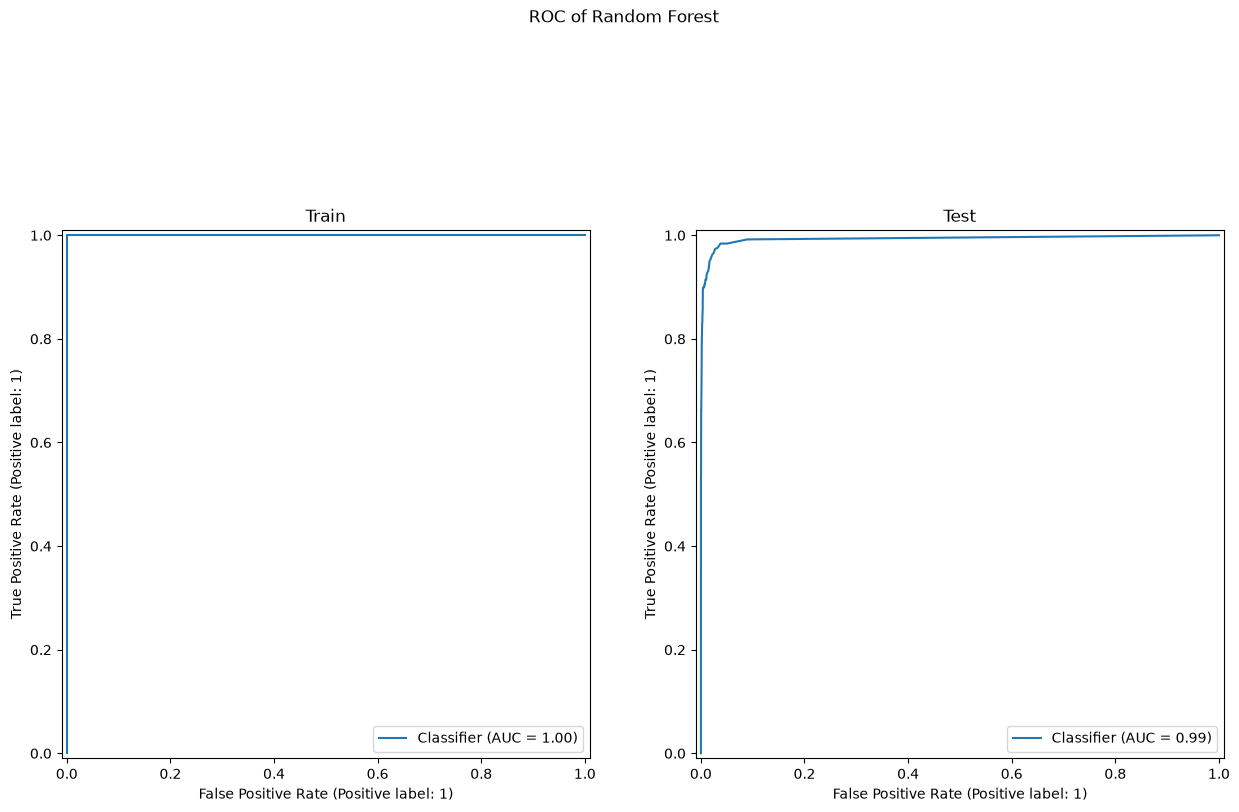

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 10))
RocCurveDisplay.from_predictions(y_train, y_prob_train, ax=axes[0])
axes[0].set_title('Train')
RocCurveDisplay.from_predictions(y_test, y_prob_test, ax=axes[1])
axes[1].set_title('Test')
plt.suptitle('ROC of Random Forest')
plt.show()

In [22]:
train_error = 1 - accuracy_score(y_train, y_pred_train)
test_error = 1 - accuracy_score(y_test, y_pred_test)
oob_error = 1 - random_forest.oob_score_
train_auc = roc_auc_score(y_train, y_prob_train)
test_auc = roc_auc_score(y_test, y_prob_test)

print(f'Train error: {train_error}')
print(f'Test error: {test_error}')
print(f'OOB error: {oob_error}')
print(f'Train AUC: {train_auc}')
print(f'Test AUC: {test_auc}')

Train error: 0.0
Test error: 0.007874999999999965
OOB error: 0.006149999999999989
Train AUC: 1.0
Test AUC: 0.99303424


The Out of Bag error is lower than the test error but not by much.

### (d) Research class imbalance in random forest

Class imbalance in random forests is handled by applying a penalty weight that is proportional to the frequencies of classes or by resampling the data to a balanced set by undersampling the overrepresented class. In order to keep the full data set, I will use the weighting method.

In [23]:
random_forest_balanced = RandomForestClassifier(random_state=552, oob_score=True, class_weight='balanced_subsample')
random_forest_balanced.fit(x_train, y_train)


y_pred_train_balanced = random_forest_balanced.predict(x_train)
y_pred_test_balanced = random_forest_balanced.predict(x_test)
y_prob_train_balanced = random_forest_balanced.predict_proba(x_train)[:, 1]
y_prob_test_balanced = random_forest_balanced.predict_proba(x_test)[:, 1]

In [24]:
pretty_train_confusion_matrix_balanced = pd.DataFrame(confusion_matrix(y_train, y_pred_train_balanced), columns=['Predicted neg', 'Predicted pos'], index=['Actual neg', 'Actual pos'])
print('Train set (with balanced Random Forest):')
pretty_train_confusion_matrix_balanced

Train set (with balanced Random Forest):


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,0,1000


In [25]:
pretty_test_confusion_matrix_balanced = pd.DataFrame(confusion_matrix(y_test, y_pred_test_balanced), columns=['Predicted neg', 'Predicted pos'], index=['Actual neg', 'Actual pos'])
print('Test set (with balanced Random Forest):')
pretty_test_confusion_matrix_balanced

Test set (with balanced Random Forest):


,Predicted neg,Predicted pos
Actual neg,15610,15
Actual pos,161,214


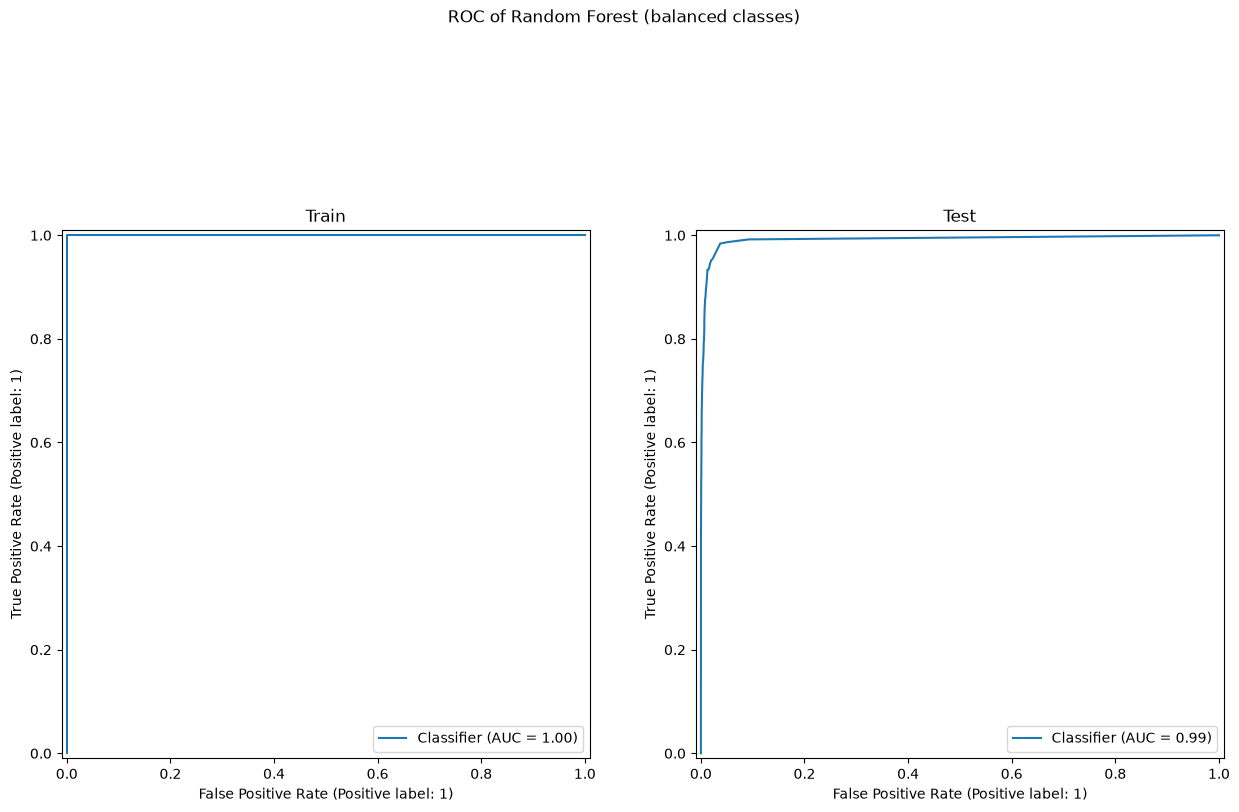

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 10))
RocCurveDisplay.from_predictions(y_train, y_prob_train_balanced, ax=axes[0])
axes[0].set_title('Train')
RocCurveDisplay.from_predictions(y_test, y_prob_test_balanced, ax=axes[1])
axes[1].set_title('Test')
plt.suptitle('ROC of Random Forest (balanced classes)')
plt.show()

In [27]:
train_error_balanced = 1 - accuracy_score(y_train, y_pred_train_balanced)
test_error_balanced = 1 - accuracy_score(y_test, y_pred_test_balanced)
oob_error_balanced = 1 - random_forest_balanced.oob_score_
train_auc_balanced = roc_auc_score(y_train, y_prob_train_balanced)
test_auc_balanced = roc_auc_score(y_test, y_prob_test_balanced)

print('Random Forest with balanced classes')
print(f'Train error: {train_error_balanced}')
print(f'Test error: {test_error_balanced}')
print(f'OOB error: {oob_error_balanced}')
print(f'Train AUC: {train_auc_balanced}')
print(f'Test AUC: {test_auc_balanced}')

Random Forest with balanced classes
Train error: 0.0
Test error: 0.01100000000000001
OOB error: 0.007816666666666694
Train AUC: 1.0
Test AUC: 0.9920390826666666


With classes balanced, the training error remains zero, but the test error increases to 0.0110 as opposed the unbalanced random forest's test error of 0.0079 and the Out of Bag error increases to 0.0078 from 0.0061.

### (e) XGBoost and Model Trees

In [28]:
alpha = [0, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]
XGB = XGBClassifier(random_state=552, objective='binary:logistic', eval_metric='logloss')
k = StratifiedKFold(random_state=552, n_splits=5, shuffle=True)
XGB_grid = GridSearchCV(XGB, cv=k, param_grid={'reg_alpha': alpha}, scoring='accuracy')
XGB_grid.fit(x_train, y_train)

print(pd.DataFrame(XGB_grid.cv_results_)[['param_reg_alpha', 'mean_test_score']])
print(f'Best alpha value: {XGB_grid.best_params_['reg_alpha']}')
print(f'Error: {1 - XGB_grid.best_score_}')

   param_reg_alpha  mean_test_score
0             0.00         0.993500
1             0.05         0.993567
2             0.10         0.993600
3             0.50         0.993417
4             1.00         0.993417
5             5.00         0.993017
6            10.00         0.991650
7            50.00         0.989717
8           100.00         0.988617
Best alpha value: 0.1
Error: 0.006399999999999961


In [29]:
XGB_model = XGB_grid.best_estimator_
y_pred_train_XGB = XGB_model.predict(x_train)
y_pred_test_XGB = XGB_model.predict(x_test)
y_prob_train_XGB = XGB_model.predict_proba(x_train)[:, 1]
y_prob_test_XGB = XGB_model.predict_proba(x_test)[:, 1]

In [30]:
pretty_train_confusion_matrix = pd.DataFrame(confusion_matrix(y_train, y_pred_train_XGB), columns=['Predicted neg', 'Predicted pos'], index=['Actual neg', 'Actual pos'])
print('XGB Train set:')
pretty_train_confusion_matrix

XGB Train set:


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,1,999


In [31]:
pretty_train_confusion_matrix = pd.DataFrame(confusion_matrix(y_test, y_pred_test_XGB), columns=['Predicted neg', 'Predicted pos'], index=['Actual neg', 'Actual pos'])
print('XGB Test set:')
pretty_train_confusion_matrix

XGB Test set:


,Predicted neg,Predicted pos
Actual neg,15605,20
Actual pos,83,292


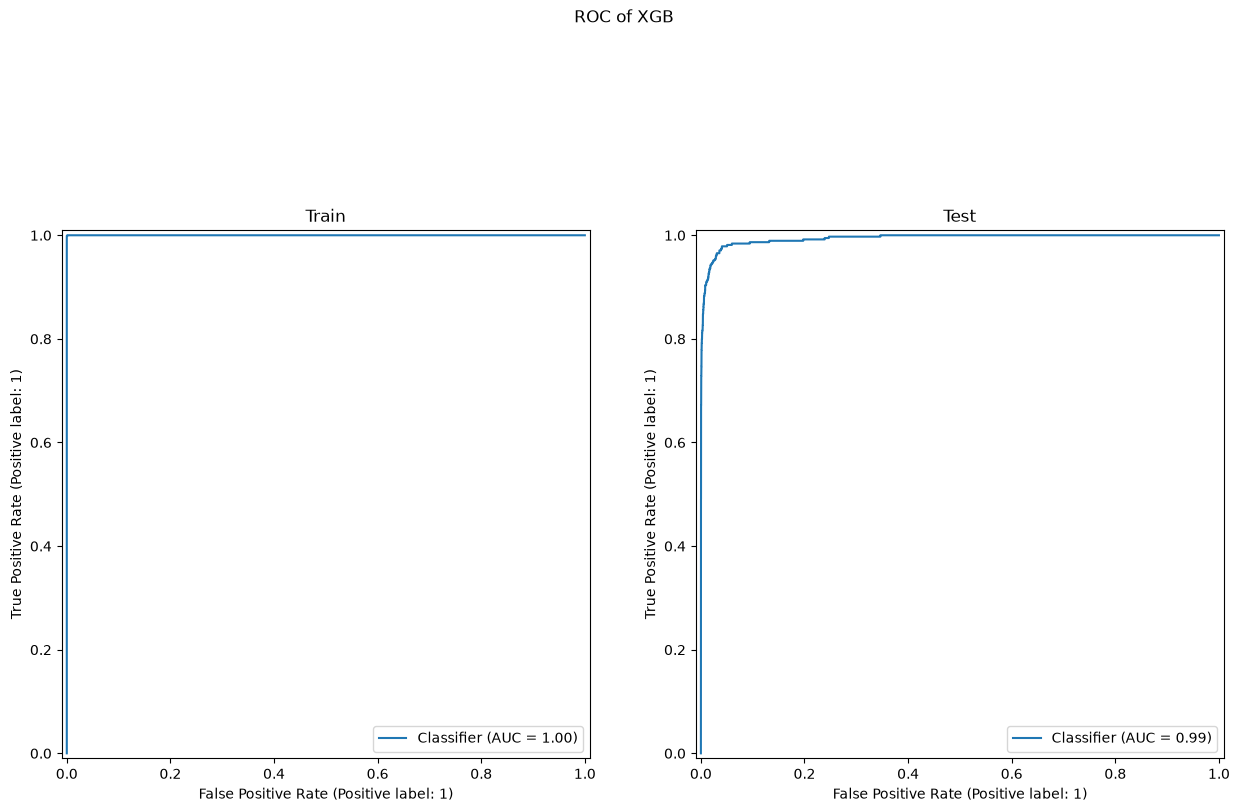

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 10))
RocCurveDisplay.from_predictions(y_train, y_prob_train_XGB, ax=axes[0])
axes[0].set_title('Train')
RocCurveDisplay.from_predictions(y_test, y_prob_test_XGB, ax=axes[1])
axes[1].set_title('Test')
plt.suptitle('ROC of XGB')
plt.show()

In [33]:
train_error_XGB = 1 - accuracy_score(y_train, y_pred_train_XGB)
test_error_XGB = 1 - accuracy_score(y_test, y_pred_test_XGB)
train_auc_XGB = roc_auc_score(y_train, y_prob_train_XGB)
test_auc_XGB = roc_auc_score(y_test, y_prob_test_XGB)

print('XGB')
print(f'Train error: {train_error_XGB}')
print(f'Test error: {test_error_XGB}')
print(f'Train AUC: {train_auc_XGB}')
print(f'Test AUC: {test_auc_XGB}')

XGB
Train error: 1.666666666666483e-05
Test error: 0.006437499999999985
Train AUC: 0.9999988474576271
Test AUC: 0.9939623253333334


### (f) Use SMOTE to pre-process your data

In [34]:
workflow = Pipeline([('SMOTE', SMOTE(random_state=552)), ('XGB', XGBClassifier(random_state=552, objective='binary:logistic', eval_metric='logloss'))])
k = StratifiedKFold(random_state=552, n_splits=5, shuffle=True)
SMOTE_grid = GridSearchCV(workflow, cv=k, param_grid={'XGB__reg_alpha': alpha}, scoring='accuracy')
SMOTE_grid.fit(x_train, y_train)

print(pd.DataFrame(SMOTE_grid.cv_results_)[['param_XGB__reg_alpha', 'mean_test_score']])
print(f'Best alpha value: {SMOTE_grid.best_params_['XGB__reg_alpha']}')
print(f'Error: {1 - SMOTE_grid.best_score_}')

   param_XGB__reg_alpha  mean_test_score
0                  0.00         0.993300
1                  0.05         0.993183
2                  0.10         0.993333
3                  0.50         0.993067
4                  1.00         0.993217
5                  5.00         0.992833
6                 10.00         0.992317
7                 50.00         0.986933
8                100.00         0.982567
Best alpha value: 0.1
Error: 0.006666666666666599


In [35]:
SMOTE_model = SMOTE_grid.best_estimator_
y_pred_train_SMOTE = SMOTE_model.predict(x_train)
y_pred_test_SMOTE = SMOTE_model.predict(x_test)
y_prob_train_SMOTE = SMOTE_model.predict_proba(x_train)[:, 1]
y_prob_test_SMOTE = SMOTE_model.predict_proba(x_test)[:, 1]

In [36]:
pretty_train_confusion_matrix_SMOTE = pd.DataFrame(confusion_matrix(y_train, y_pred_train_SMOTE), columns=['Predicted neg', 'Predicted pos'], index=['Actual neg', 'Actual pos'])
print('SMOTE Train set:')
pretty_train_confusion_matrix_SMOTE

SMOTE Train set:


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,1,999


In [37]:
pretty_test_confusion_matrix_SMOTE = pd.DataFrame(confusion_matrix(y_test, y_pred_test_SMOTE), columns=['Predicted neg', 'Predicted pos'], index=['Actual neg', 'Actual pos'])
print('SMOTE Test set:')
pretty_test_confusion_matrix_SMOTE

SMOTE Test set:


,Predicted neg,Predicted pos
Actual neg,15556,69
Actual pos,54,321


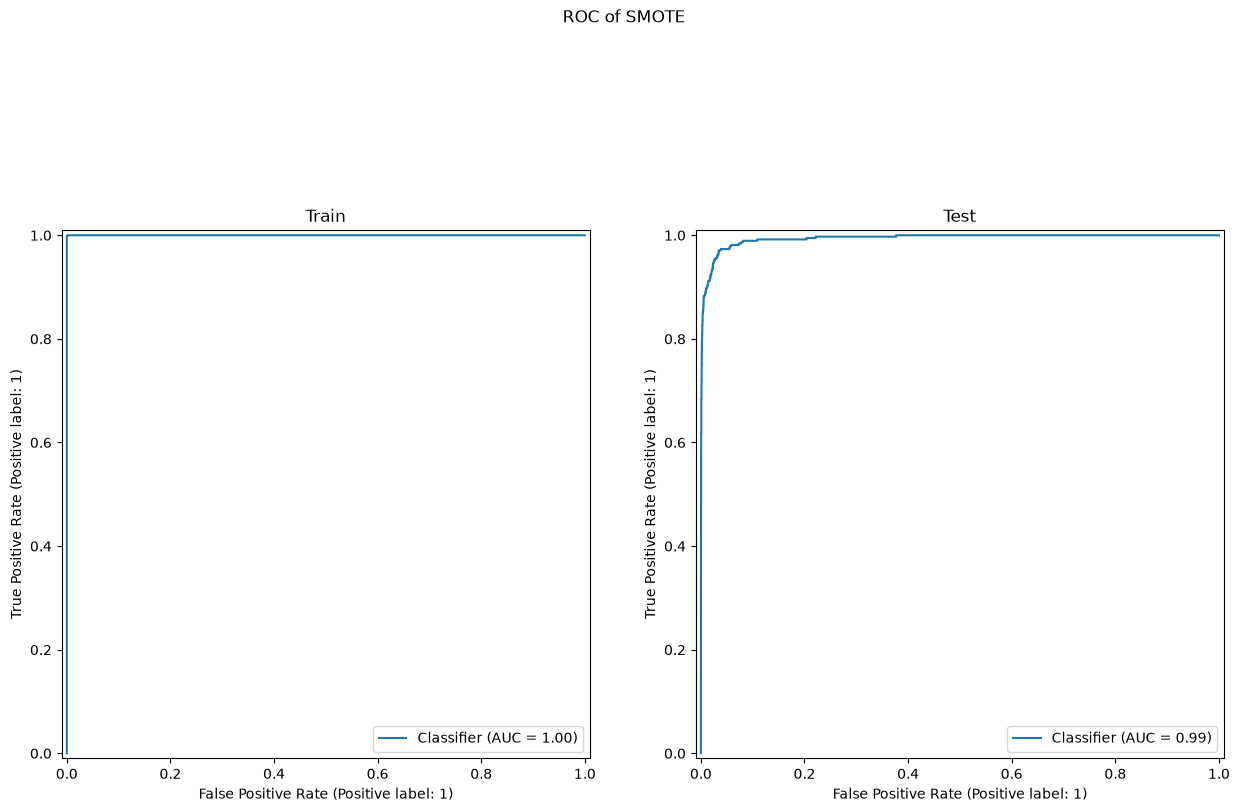

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 10))
RocCurveDisplay.from_predictions(y_train, y_prob_train_SMOTE, ax=axes[0])
axes[0].set_title('Train')
RocCurveDisplay.from_predictions(y_test, y_prob_test_SMOTE, ax=axes[1])
axes[1].set_title('Test')
plt.suptitle('ROC of SMOTE')
plt.show()

In [39]:
train_error_SMOTE = 1 - accuracy_score(y_train, y_pred_train_SMOTE)
test_error_SMOTE = 1 - accuracy_score(y_test, y_pred_test_SMOTE)
train_auc_SMOTE = roc_auc_score(y_train, y_prob_train_SMOTE)
test_auc_SMOTE = roc_auc_score(y_test, y_prob_test_SMOTE)

print('SMOTE')
print(f'Train error: {train_error_SMOTE}')
print(f'Test error: {test_error_SMOTE}')
print(f'Train AUC: {train_auc_SMOTE}')
print(f'Test AUC: {test_auc_SMOTE}')

SMOTE
Train error: 1.666666666666483e-05
Test error: 0.007687499999999958
Train AUC: 0.9999981610169492
Test AUC: 0.9939800746666667


Although both methods have the same training error, XGBoost without SMOTE had the better test error of 0.0064 as opposed to the test error with SMOTE of 0.0077.

## 2. ISLR 6.6.3

(a) iv. Training RSS will steadily decrease as the larger s gives the model more options to minimize RSS.
<br>
(b) ii. Test RSS will decrease intially as the model goes from underfit to fitting, but eventually it will overfit.
<br>
(c) iii. Variance will steadily increase as the a larger s reduces constraints.
<br>
(d) iv. Squared bias will steadily decrease as a less constrained s allows the model to fit closer to the true relationship.
<br>
(e) v. Irreducible error is not dependant on s so it will stay constant.


## 3. ISLR 6.6.5

$a = x_{11} = x_{12}$
<br>
$x_{21} = x_{22} = -a$
<br>
$y_{2} = -y_{1}$
<br>
$\beta_{0} = 0$
<br>
$S = \beta_{1} + \beta_{2}$
<br>
$\beta_{1}x_{11}+\beta_{2}x_{12}=a\beta_{1}+a\beta_{2} = aS$
<br>
$\beta_{1}x_{21}+\beta_{2}x_{22}=-a\beta_{1}-a\beta_{2} = -aS$

Residuals
<br>
$y_{1} - aS$
<br>
$y_{2} - aS$

Sum of squares
<br>
$(y_{2} + aS)^{2} = (-y_{1} + aS)^{2} = (y_{1} - aS)^{2}$
<br>
$(y_{1} - aS)^{2} + (y_{2} + aS)^{2} = 2(y_{1} - aS)^{2}$

**(a)**
<br>
Minimize
<br>
$(y_{1}-\beta_{1}x_{11}-\beta_{2}x_{12})^{2} + (y_{2}-\beta_{1}x_{21}-\beta_{2}x_{22})^{2} + \lambda(\beta_{1}^{2}+\beta_{2}^{2})$
<br>
$2(y_{1} - a(\beta_{1} + \beta_{2}))^{2} + \lambda(\beta_{1}^{2} + \beta_{2}^{2})$


**(b)**
<br>
The error term is dependant on $\beta_{1}$ and $\beta_{2}$ by $S = \beta_{1} + \beta_{2}$. Since the $\frac{1}{2}S^{2}$ term is fixed, for $\frac{1}{2}(\beta_{1}-\beta_{2})^{2}$ to reach zero, $\beta_{1}=\beta_{2}$ must equal 0.


**(c)**
<br>
Minimize
<br>
$(y_{1}-\beta_{1}x_{11}-\beta_{2}x_{12})^{2} + (y_{2}-\beta_{1}x_{21}-\beta_{2}x_{22})^{2} + \lambda(\beta_{1}^{2}+\beta_{2}^{2})$
<br>
$a = x_{11} = x_{12}$
<br>
$x_{21} = x_{22} = -a$
<br>
$2(y_{1}-a(\beta_{1}+\beta_{2}))^{2} + \lambda(\beta_{1}^{2}+\beta_{2}^{2})
$


**(d)**
<br>
Ridge regression uses a circular shape so the error line only touches a single point on the cirle. This results in one unique solution. Lasso regression uses a diamond shape. This means that the error line makes contact with a whole edge of the diamond, resulting in many contact points that are solutions.

## 4. ISLR 8.4.5

0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75
<br>

Using majority vote, it would be classified as red. There are 6 votes above 0.5 and 4 votes below 0.5.

<br>

0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75 = 4.5

4.5/10 = 0.45

Using average probabilty, it would be classified as green.

## 5. ISLR 9.7.3

(a) See .png for chart
<br>
(b) 
<br>
$0.5 - 1*X_{1} + 1X_{2} = 0$
<br>
See .png for chart
<br>
(c)
<br>
If $0.5 - 1*X_{1} + 1X_{2} > 0$, classify as red, otherwise classify as blue. B0 = 0.5, B1 = -1, B2 = 1
<br>
(d) See .png for chart
<br>
(e) The support vectors are the observation points: 2, 3, 5, 6
<br>
(f) The hyperplane's position depends on the support vectors, so slightly moving the 7th observation does not impact the hyperplane unless it moves past a support vector.
<br>
(g) See .png for chart
<br>
(h) Adding the observation (2, 4) as a blue point makes it so that the classes are no longer separated. See .png for chart